In [1]:
from google.colab import drive

drive.mount('/content/drive')
base = "/content/drive/MyDrive/UTokyo/Proteome"

Mounted at /content/drive


In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 11.4 MB/s  0:00:00


# BUSCO

In [ ]:
busco -i ~/busco_input \
      -m proteins \
      -l alveolata_odb12 \
      --download_path ~/busco_downloads \
      -c 8 \
      -o symbio_busco \
      --out_path ~/busco_out

# Proteome size, BUSCO score, secretome size

Species  Whole  NonRedundant  Redundancy_pct  BUSCO_C  Classical_final  Unconventional_final  Total_pct
   Spil  23335         23249        0.368545     56.6              406                   115   2.240957
   Snat  35270         34375        2.537567     70.7              983                   274   3.656727
   Stri  45474         41779        8.125522     71.7             1066                   277   3.214534
   Slin  32053         32002        0.159111     79.8              807                   191   3.118555
   Snec  35671         35566        0.294357     69.7              782                   199   2.758252
   Smic  43403         42915        1.124346     75.7              599                   192   1.843178
   Bmin  47014         45245        3.762709     64.6              752                   232   2.174826


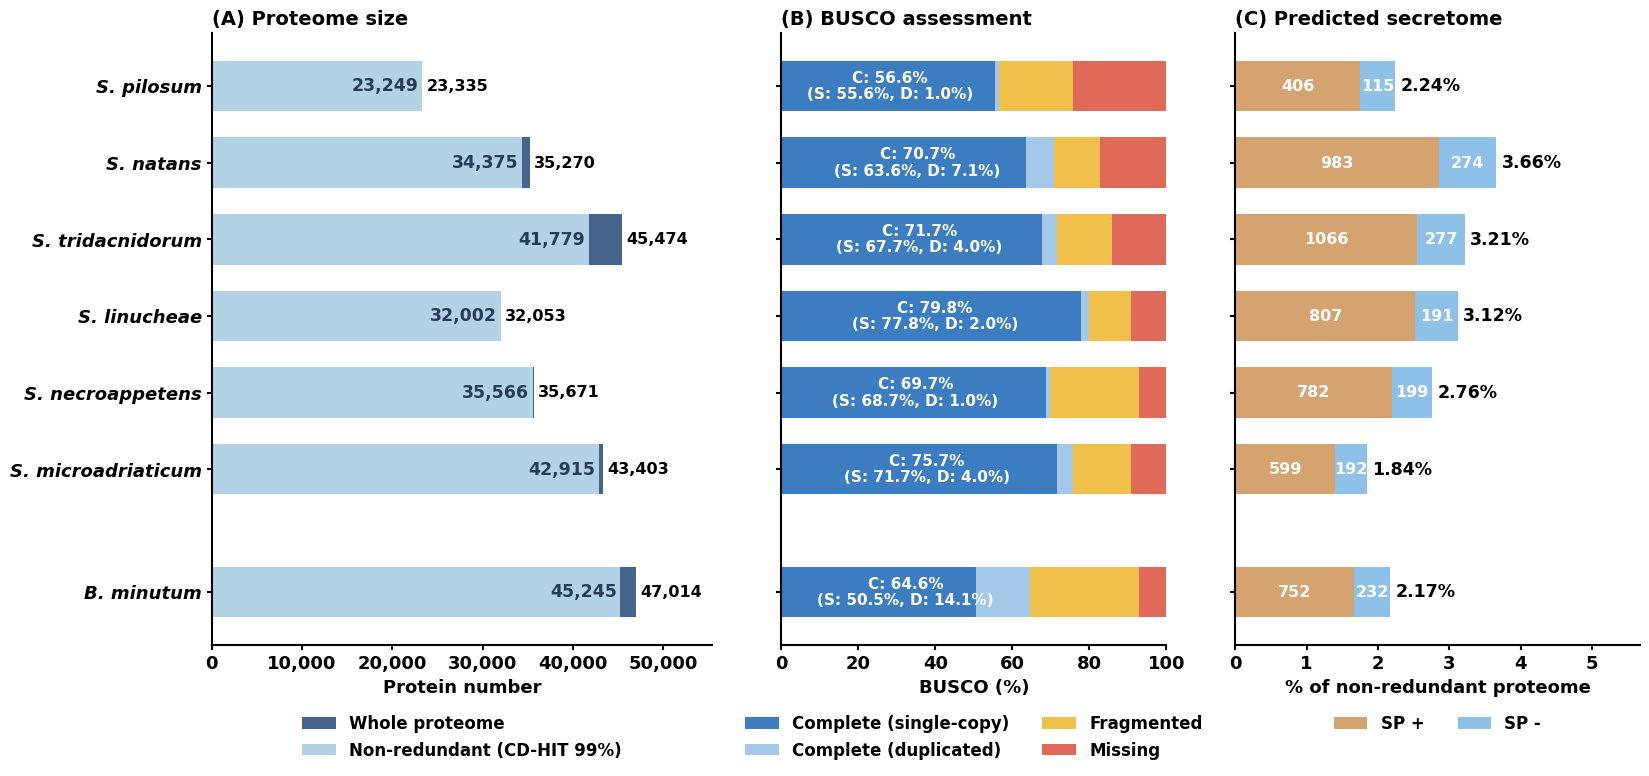


Saved:
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/proteome_busco_secretome_summary.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_proteome_busco_secretome.png
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_proteome_busco_secretome.pdf
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_proteome_busco_secretome.svg


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from Bio import SeqIO

# ============================================================
# PATHS
# ============================================================
proteome_dir = os.path.join(base, "Proteome_11sp")
project_path = os.path.join(base, "Prediction_vs_Detection")
base_dir     = project_path

data_pre = os.path.join(base, "Publication", "data_pre")
fig_pre  = os.path.join(base, "Publication", "figures_pre")
os.makedirs(data_pre, exist_ok=True)
os.makedirs(fig_pre,  exist_ok=True)

busco_tsv = os.path.join(data_pre, "busco_scores_alveolata_odb12.tsv")

# ============================================================
# SPECIES + DISPLAY  (7 strains: 6 Symbiodinium + 1 Breviolum)
# ============================================================
species_order = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic", "Bmin"]

label_map = {
    "Spil": "S. pilosum",
    "Snat": "S. natans",
    "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae",
    "Snec": "S. necroappetens",
    "Smic": "S. microadriaticum",
    "Bmin": "B. minutum",
}

fs_prefix = {
    "Spil": "Spil", "Snat": "Snat", "Stri": "Stri", "Slin": "Slin",
    "Snec": "Snec", "Smic": "Smic_jgi", "Bmin": "Bmin",
}

clade_groups = [
    ("Symbiodinium (clade A)", ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic"]),
    ("Breviolum (clade B)",    ["Bmin"]),
]
species_to_clade = {sp: name for name, members in clade_groups for sp in members}

# ============================================================
# PATH HELPERS
# ============================================================
def whole_proteome_path(sp):
    return os.path.join(proteome_dir, f"{sp}.faa")

def nr_proteome_path(prefix):
    return os.path.join(base_dir, prefix, "01_cdhit", f"{prefix}_nr99.faa")

def secretome_pos_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_pos_secretome_final.faa")

def secretome_neg_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_neg_secretome_final.faa")

def count_fasta(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing FASTA: {path}")
    return sum(1 for _ in SeqIO.parse(path, "fasta"))

# ============================================================
# BUSCO  — read from uploaded TSV (by column name)
# ============================================================
busco_raw = pd.read_csv(busco_tsv, sep="\t")
if "Species" not in busco_raw.columns:
    raise KeyError(f"'Species' column not found in {busco_tsv}. "
                   f"Columns present: {list(busco_raw.columns)}")
busco_raw = busco_raw.set_index("Species")

_BUSCO_COLS = {"S": "Single_S", "D": "Duplicated_D",
               "F": "Fragmented_F", "M": "Missing_M"}

def get_busco(sp):
    if sp not in busco_raw.index:
        raise KeyError(f"No BUSCO row for '{sp}' in {os.path.basename(busco_tsv)}. "
                       f"Rows present: {list(busco_raw.index)}")
    row = busco_raw.loc[sp]
    return {k: float(row[col]) for k, col in _BUSCO_COLS.items()}

# ============================================================
# BUILD DATAFRAME
# ============================================================
records = []
for sp in species_order:
    prefix = fs_prefix[sp]
    b = get_busco(sp)
    records.append({
        "Species":              sp,
        "Whole":                count_fasta(whole_proteome_path(sp)),
        "NonRedundant":         count_fasta(nr_proteome_path(prefix)),
        "Classical_final":      count_fasta(secretome_pos_path(prefix)),
        "Unconventional_final": count_fasta(secretome_neg_path(prefix)),
        "BUSCO_S": b["S"], "BUSCO_D": b["D"], "BUSCO_F": b["F"], "BUSCO_M": b["M"],
    })
df = pd.DataFrame(records)
df["Species"] = pd.Categorical(df["Species"], categories=species_order, ordered=True)
df = df.sort_values("Species").reset_index(drop=True)

df["Redundancy_pct"]     = (1 - df["NonRedundant"] / df["Whole"]) * 100
df["Classical_pct"]      = df["Classical_final"]      / df["NonRedundant"] * 100
df["Unconventional_pct"] = df["Unconventional_final"] / df["NonRedundant"] * 100
df["Total_pct"]          = df["Classical_pct"] + df["Unconventional_pct"]
df["BUSCO_C"]            = df["BUSCO_S"] + df["BUSCO_D"]

summary_tsv = os.path.join(data_pre, "proteome_busco_secretome_summary.tsv")
df.to_csv(summary_tsv, sep="\t", index=False)
print(df[[
    "Species", "Whole", "NonRedundant", "Redundancy_pct", "BUSCO_C",
    "Classical_final", "Unconventional_final", "Total_pct"
]].to_string(index=False))

# ============================================================
# STYLE
# ============================================================
plt.rcParams["svg.fonttype"]     = "none"
plt.rcParams["font.weight"]      = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

whole_color    = (70/255, 100/255, 140/255)
nr_color       = (180/255, 210/255, 230/255)
nr_label_color = (40/255, 60/255, 90/255)

busco_S, busco_D = "#3C7DC2", "#A4C8E8"
busco_F, busco_M = "#F0C04A", "#E06A5A"

classical_color      = (213/255, 163/255, 112/255)   # SP+
unconventional_color = (142/255, 193/255, 231/255)   # SP-

bar_h = 0.66

# ============================================================
# Y POSITIONS (with clade gap between Smic and Bmin)
# ============================================================
plot_labels = [label_map[s] for s in df["Species"]]
y = []
running = 0.0
prev_clade = None
for sp in df["Species"]:
    this_clade = species_to_clade[sp]
    if prev_clade is not None and this_clade != prev_clade:
        running += 0.6
    y.append(running)
    running += 1.0
    prev_clade = this_clade
y = np.array(y)

# ============================================================
# FIGURE — 1 x 3, shared species axis
# ============================================================
fig, (axP, axB, axS) = plt.subplots(
    1, 3, figsize=(17, 8.5), sharey=True,
    gridspec_kw={"width_ratios": [1.3, 1.0, 1.05], "wspace": 0.16}
)

# ---------- Panel A: Proteome size ----------
axP.barh(y, df["Whole"], height=bar_h, color=whole_color, label="Whole proteome")
axP.barh(y, df["NonRedundant"], height=bar_h, color=nr_color,
         label="Non-redundant (CD-HIT 99%)")

xmaxP = df["Whole"].max()
pad, inner_pad = xmaxP * 0.01, xmaxP * 0.008
for i in range(len(df)):
    w, n = int(df["Whole"].iloc[i]), int(df["NonRedundant"].iloc[i])
    axP.text(w + pad, y[i], f"{w:,}", va="center", ha="left",
             fontsize=11.5, fontweight="bold", color="black")
    axP.text(n - inner_pad, y[i], f"{n:,}", va="center", ha="right",
             fontsize=12.5, fontweight="bold", color=nr_label_color)
axP.set_xlim(0, xmaxP * 1.18)
axP.set_xlabel("Protein number", fontsize=13, fontweight="bold")
axP.set_title("(A) Proteome size", loc="left", fontsize=14, fontweight="bold")
axP.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))

# ---------- Panel B: BUSCO completeness ----------
left = np.zeros(len(df))
for key, col, lab in [("BUSCO_S", busco_S, "Complete (single-copy)"),
                      ("BUSCO_D", busco_D, "Complete (duplicated)"),
                      ("BUSCO_F", busco_F, "Fragmented"),
                      ("BUSCO_M", busco_M, "Missing")]:
    axB.barh(y, df[key], height=bar_h, left=left, color=col, label=lab)
    left += df[key].values
for i in range(len(df)):
    c = df["BUSCO_C"].iloc[i]
    s = df["BUSCO_S"].iloc[i]
    d = df["BUSCO_D"].iloc[i]
    axB.text(c / 2, y[i],
             f"C: {c:.1f}%\n(S: {s:.1f}%, D: {d:.1f}%)",
             va="center", ha="center",
             color="white", fontsize=11, fontweight="bold",
             linespacing=1.1)

axB.set_xlim(0, 100)
axB.set_xlabel("BUSCO (%)", fontsize=13, fontweight="bold")
axB.set_title("(B) BUSCO assessment", loc="left", fontsize=14, fontweight="bold")
axB.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v)}"))

# ---------- Panel C: secretome as % of NR proteome  (+ protein counts) ----------
axS.barh(y, df["Classical_pct"], height=bar_h,
         color=classical_color, label="SP +")
axS.barh(y, df["Unconventional_pct"], height=bar_h, left=df["Classical_pct"],
         color=unconventional_color, label="SP -")

xmaxS = df["Total_pct"].max()
# minimum segment width (in % units) needed to hold a count label inside the bar
inner_thr = xmaxS * 0.09
for i in range(len(df)):
    c_pct = df["Classical_pct"].iloc[i]
    u_pct = df["Unconventional_pct"].iloc[i]
    t_pct = df["Total_pct"].iloc[i]
    c_n   = int(df["Classical_final"].iloc[i])
    u_n   = int(df["Unconventional_final"].iloc[i])

    spill = []  # counts that don't fit inside their segment -> shown at bar end

    # SP+ count inside the classical segment
    if c_pct >= inner_thr:
        axS.text(c_pct / 2, y[i], f"{c_n}", va="center", ha="center",
                 color="white", fontsize=11.5, fontweight="bold")
    else:
        spill.append(f"SP+ {c_n}")

    # SP- count inside the unconventional segment
    if u_pct >= inner_thr:
        axS.text(c_pct + u_pct / 2, y[i], f"{u_n}", va="center", ha="center",
                 color="white", fontsize=11.5, fontweight="bold")
    else:
        spill.append(f"SP- {u_n}")

    # end-of-bar label: total %, plus any counts that didn't fit inside
    end_txt = f"{t_pct:.2f}%"
    if spill:
        end_txt += "  (" + ", ".join(spill) + ")"
    axS.text(t_pct + xmaxS * 0.02, y[i], end_txt, va="center", ha="left",
             fontsize=12.5, fontweight="bold", color="black")

axS.set_xlim(0, xmaxS * 1.55)
axS.set_xlabel("% of non-redundant proteome", fontsize=13, fontweight="bold")
axS.set_title("(C) Predicted secretome", loc="left", fontsize=14, fontweight="bold")

# ---------- shared y-axis (leftmost only) ----------
axP.set_yticks(y)
axP.set_yticklabels(plot_labels, fontsize=12)
for tick in axP.get_yticklabels():
    tick.set_fontstyle("italic")
    tick.set_fontweight("bold")
axP.invert_yaxis()

# ---------- common spine / tick styling ----------
for ax in (axP, axB, axS):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=13, width=1.5)
    for tlbl in ax.get_xticklabels():
        tlbl.set_fontweight("bold")

# ---------- per-panel legends below each axis ----------
for ax, ncol in [(axP, 1), (axB, 2), (axS, 2)]:
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09),
                    ncol=ncol, frameon=False, fontsize=12)
    for t in leg.get_texts():
        t.set_fontweight("bold")

fig.subplots_adjust(left=0.13, right=0.97, top=0.92, bottom=0.20, wspace=0.16)

# ============================================================
# SAVE
# ============================================================
stem = os.path.join(fig_pre, "Fig_proteome_busco_secretome")
for ext in ("png", "pdf", "svg"):
    fig.savefig(f"{stem}.{ext}",
                dpi=600 if ext == "png" else None, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(summary_tsv)
for ext in ("png", "pdf", "svg"):
    print(f"{stem}.{ext}")

# Protein length, % cysteine, kDa

Category  Classical  Proteome  Unconventional
Species                                      
Bmin            752     45245             232
Slin            807     32002             191
Smic            599     42915             192
Snat            983     34375             274
Snec            782     35566             199
Spil            406     23249             115
Stri           1066     41779             277
Saved feature table to: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/protein_features_for_violin.tsv


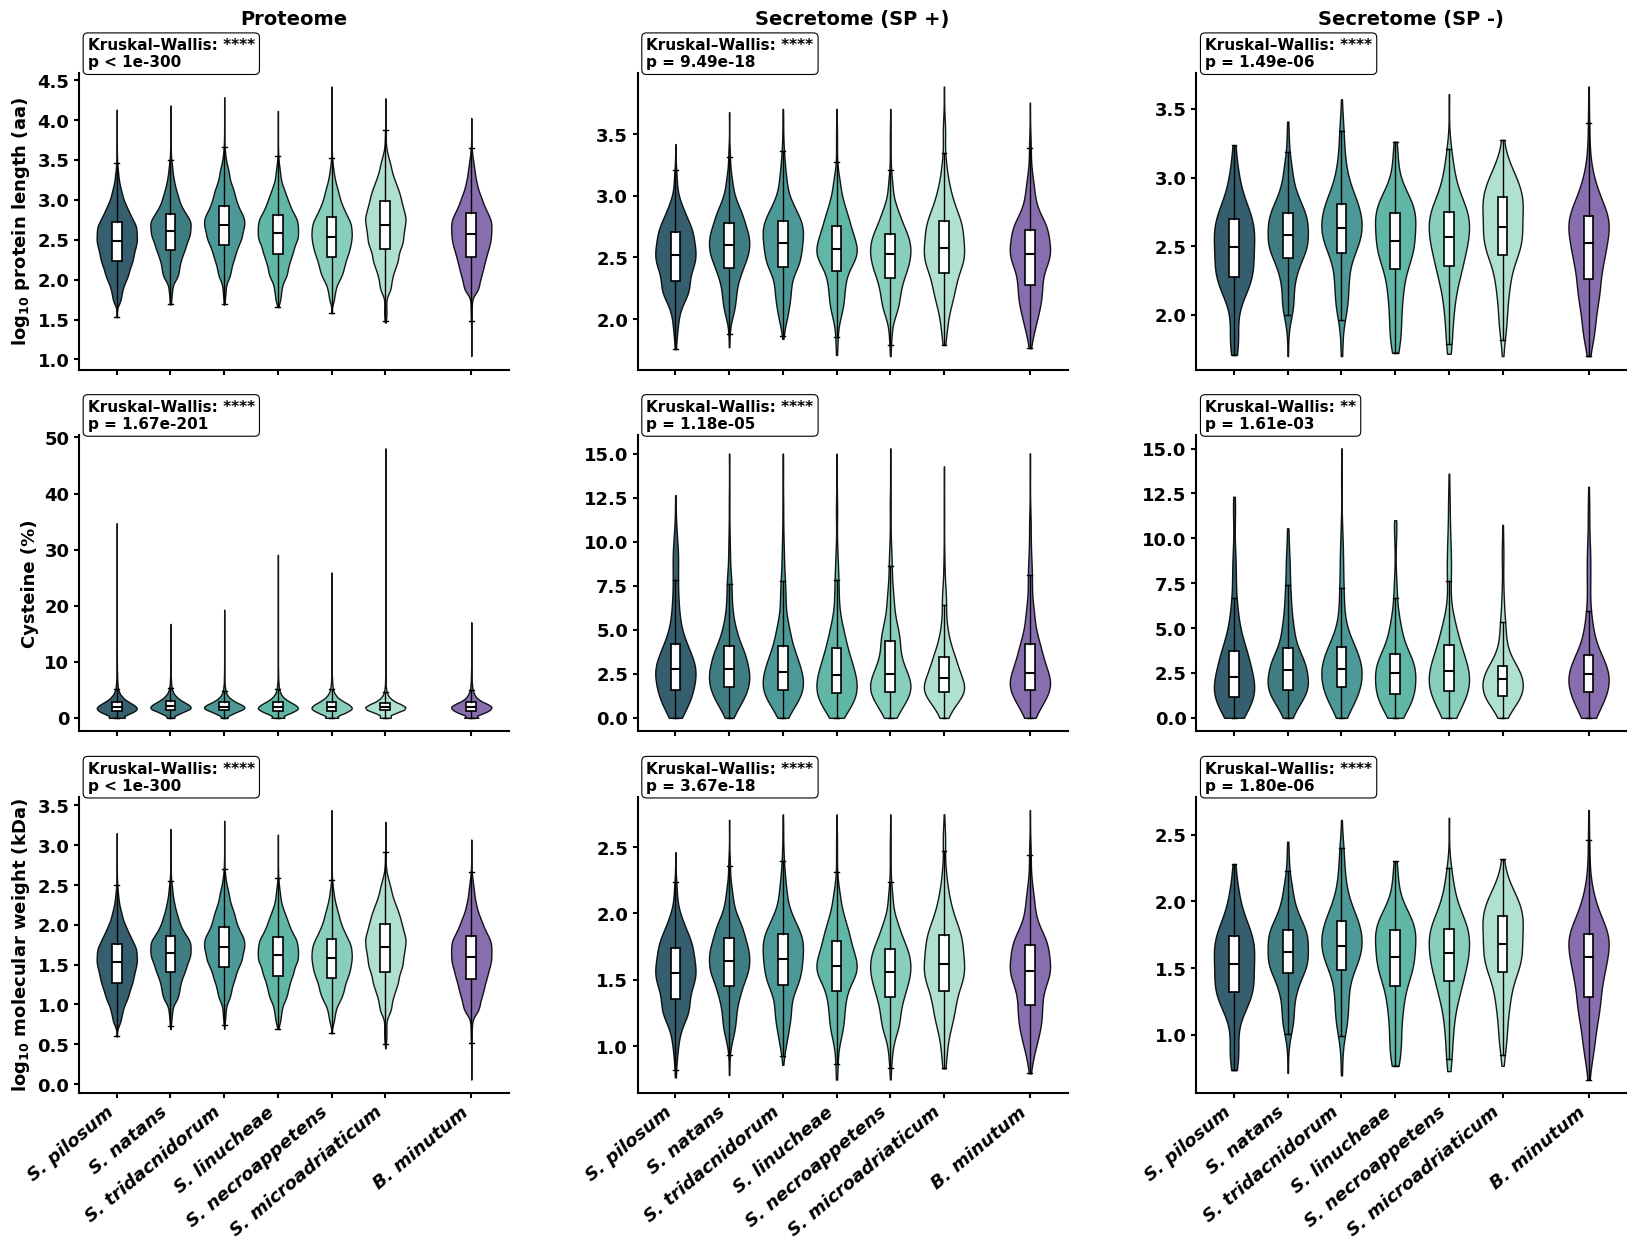


Saved:
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/protein_features_for_violin.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_protein_features_violin.png
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_protein_features_violin.pdf
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_protein_features_violin.svg


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.SeqUtils import molecular_weight
from scipy.stats import kruskal

# ============================================================
# PATHS
# ============================================================
proteome_dir = os.path.join(base, "Proteome_11sp")
project_path = os.path.join(base, "Prediction_vs_Detection")
base_dir     = project_path

data_pre = os.path.join(base, "Publication", "data_pre")
fig_pre  = os.path.join(base, "Publication", "figures_pre")
os.makedirs(data_pre, exist_ok=True)
os.makedirs(fig_pre,  exist_ok=True)

feature_tsv = os.path.join(data_pre, "protein_features_for_violin.tsv")

# ============================================================
# SPECIES + DISPLAY  (7 strains: 6 Symbiodinium + 1 Breviolum)
# ============================================================
species_order = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic", "Bmin"]

label_map = {
    "Spil": "S. pilosum",
    "Snat": "S. natans",
    "Stri": "S. tridacnidorum",
    "Slin": "S. linucheae",
    "Snec": "S. necroappetens",
    "Smic": "S. microadriaticum",
    "Bmin": "B. minutum",
}

fs_prefix = {
    "Spil": "Spil", "Snat": "Snat", "Stri": "Stri", "Slin": "Slin",
    "Snec": "Snec", "Smic": "Smic_jgi", "Bmin": "Bmin",
}

clade_groups = [
    ("Symbiodinium (clade A)", ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic"]),
    ("Breviolum (clade B)",    ["Bmin"]),
]
species_to_clade = {sp: name for name, members in clade_groups for sp in members}

# ============================================================
# FASTA PATH HELPERS
# ============================================================
def nr_proteome_path(prefix):
    return os.path.join(base_dir, prefix, "01_cdhit", f"{prefix}_nr99.faa")
def secretome_pos_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_pos_secretome_final.faa")
def secretome_neg_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_neg_secretome_final.faa")

CATEGORY_ORDER  = ["Proteome", "Classical", "Unconventional"]
CATEGORY_LABELS = ["Proteome", "Secretome (SP +)", "Secretome (SP -)"]

files = {}
for sp in species_order:
    prefix = fs_prefix[sp]
    files[(sp, "Proteome")]       = nr_proteome_path(prefix)
    files[(sp, "Classical")]      = secretome_pos_path(prefix)
    files[(sp, "Unconventional")] = secretome_neg_path(prefix)

# ============================================================
# FEATURE CALCULATION
# ============================================================
def calc_features(record):
    seq = str(record.seq).replace("*", "").upper()
    seq = "".join([aa for aa in seq if aa.isalpha()])
    if len(seq) == 0:
        return None
    length = len(seq)
    cys_pct = (seq.count("C") / length) * 100
    try:
        mw = molecular_weight(seq, seq_type="protein")
    except Exception:
        mw = np.nan
    return {
        "Protein_ID":     record.id.split()[0],
        "Length_aa":      length,
        "Cys_percent":    cys_pct,
        "Mol_weight_kDa": mw / 1000 if pd.notna(mw) else np.nan,
    }

rows = []
for (sp, cat), fasta in files.items():
    if not os.path.exists(fasta):
        raise FileNotFoundError(f"Missing FASTA: {fasta}")
    for record in SeqIO.parse(fasta, "fasta"):
        feat = calc_features(record)
        if feat is None:
            continue
        feat["Species"]  = sp
        feat["Category"] = cat
        rows.append(feat)
df = pd.DataFrame(rows)
df["log10_Length_aa"]      = np.log10(df["Length_aa"])
df["log10_Mol_weight_kDa"] = np.log10(df["Mol_weight_kDa"])

df.to_csv(feature_tsv, sep="\t", index=False)
print(df.groupby(["Species", "Category"]).size().unstack(fill_value=0))
print(f"Saved feature table to: {feature_tsv}")

# ============================================================
# STYLE  (aligned with the 1x3 panel figure)
# ============================================================
plt.rcParams["svg.fonttype"]     = "none"
plt.rcParams["font.weight"]      = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.family"]      = "DejaVu Sans"

symbiodinium_palette = ["#1F4E5F", "#2A6F75", "#3A8E8C",
                        "#4FAE9E", "#7BC9B5", "#A8DDC9"]
breviolum_color = "#7B5EA7"
species_colors = {}
sym_idx = 0
for sp in species_order:
    if species_to_clade[sp] == "Symbiodinium (clade A)":
        species_colors[sp] = symbiodinium_palette[sym_idx]; sym_idx += 1
    else:
        species_colors[sp] = breviolum_color

def p_to_stars(p):
    if p < 0.0001: return "****"
    elif p < 0.001: return "***"
    elif p < 0.01:  return "**"
    elif p < 0.05:  return "*"
    else:           return "ns"

def fmt_p(p):
    if p <= 0 or p < 1e-300:
        return "p < 1e-300"
    return f"p = {p:.2e}"

# ============================================================
# X POSITIONS (with clade gap between Smic and Bmin)
# ============================================================
positions = []
running = 1.0
prev_clade = None
clade_gap = 0.6
for sp in species_order:
    this_clade = species_to_clade[sp]
    if prev_clade is not None and this_clade != prev_clade:
        running += clade_gap
    positions.append(running)
    running += 1.0
    prev_clade = this_clade
positions = np.array(positions)
plot_labels = [label_map[s] for s in species_order]

# ============================================================
# METRICS  (no panel letters)
# ============================================================
metrics = [
    ("log10_Length_aa",      r"log$_{10}$ protein length (aa)"),
    ("Cys_percent",          "Cysteine (%)"),
    ("log10_Mol_weight_kDa", r"log$_{10}$ molecular weight (kDa)"),
]
n_rows = len(metrics)
bottom_row = n_rows - 1

# ============================================================
# FIGURE — shared species x-axis (labels on bottom row only)
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(17, 12), sharex="col")

for row_idx, (metric, ylabel) in enumerate(metrics):
    for col_idx, category in enumerate(CATEGORY_ORDER):
        ax = axes[row_idx, col_idx]

        data = [df[(df["Species"] == sp) & (df["Category"] == category)][metric]
                  .dropna().values for sp in species_order]

        # Violins
        vp = ax.violinplot(
            data, positions=positions, widths=0.75,
            showmeans=False, showmedians=False, showextrema=False,
        )
        for body, sp in zip(vp["bodies"], species_order):
            body.set_facecolor(species_colors[sp])
            body.set_edgecolor("black")
            body.set_linewidth(1.0)
            body.set_alpha(0.9)

        # Inner boxplots
        ax.boxplot(
            data, positions=positions, widths=0.18,
            patch_artist=True, showfliers=False,
            medianprops=dict(color="black", linewidth=1.5),
            boxprops=dict(facecolor="white", edgecolor="black", linewidth=1.2),
            whiskerprops=dict(color="black", linewidth=1.0),
            capprops=dict(color="black", linewidth=1.0),
        )

        # Kruskal-Wallis across all species in this panel
        nonempty = [v for v in data if len(v) > 0]
        if len(nonempty) >= 2:
            try:
                stat, p = kruskal(*nonempty)
                ax.text(0.02, 1.12,
                        f"Kruskal–Wallis: {p_to_stars(p)}\n{fmt_p(p)}",
                        transform=ax.transAxes, ha="left", va="top",
                        fontsize=11, fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                                  edgecolor="black", linewidth=0.8))
            except Exception:
                pass

        # X axis — set positions/limits on every panel for grid alignment,
        # but draw the species labels only on the bottom row.
        ax.set_xticks(positions)
        ax.set_xlim(positions[0] - 0.7, positions[-1] + 0.7)
        if row_idx == bottom_row:
            ax.set_xticklabels(plot_labels, rotation=40, ha="right", fontsize=12)
            for tick in ax.get_xticklabels():
                tick.set_fontstyle("italic")
                tick.set_fontweight("bold")
        else:
            ax.tick_params(axis="x", labelbottom=False)

        if col_idx == 0:
            ax.set_ylabel(ylabel, fontsize=13, fontweight="bold")
        if row_idx == 0:
            ax.set_title(CATEGORY_LABELS[col_idx], fontsize=14,
                         fontweight="bold", pad=35)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(1.5)
        ax.spines["bottom"].set_linewidth(1.5)
        ax.tick_params(axis="both", labelsize=13, width=1.5)
        for tick in ax.get_yticklabels():
            tick.set_fontweight("bold")

# tighter row spacing now that only the bottom row carries x-labels
plt.subplots_adjust(left=0.07, right=0.98, top=0.95, bottom=0.10,
                    wspace=0.30, hspace=0.22)

# ============================================================
# SAVE
# ============================================================
stem = os.path.join(fig_pre, "Fig_protein_features_violin")
for ext in ("png", "pdf", "svg"):
    fig.savefig(f"{stem}.{ext}", dpi=600 if ext == "png" else None, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(feature_tsv)
for ext in ("png", "pdf", "svg"):
    print(f"{stem}.{ext}")

# Protein length, % cysteine

Strain  secretome_IDs   matched  non_secretome   OK?
Spil              521       521          22728     ✓
Snat             1257      1257          33118     ✓
Stri             1343      1343          40436     ✓
Slin              998       998          31004     ✓
Snec              981       981          34585     ✓
Smic              791       791          42124     ✓
Bmin              984       984          44261     ✓

Saved feature table to: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_features.tsv
Saved stats table to: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_stats.tsv
Species      Metric  n_secretome  n_nonsecretome  median_secretome  median_nonsecretome          U      p_value  cliffs_delta effect_size
   Spil   Length_aa          521           22728        319.000000           306.000000  6177421.0 9.002672e-02      0.043370  negligible
   Snat   Length_aa         1257           33118        39

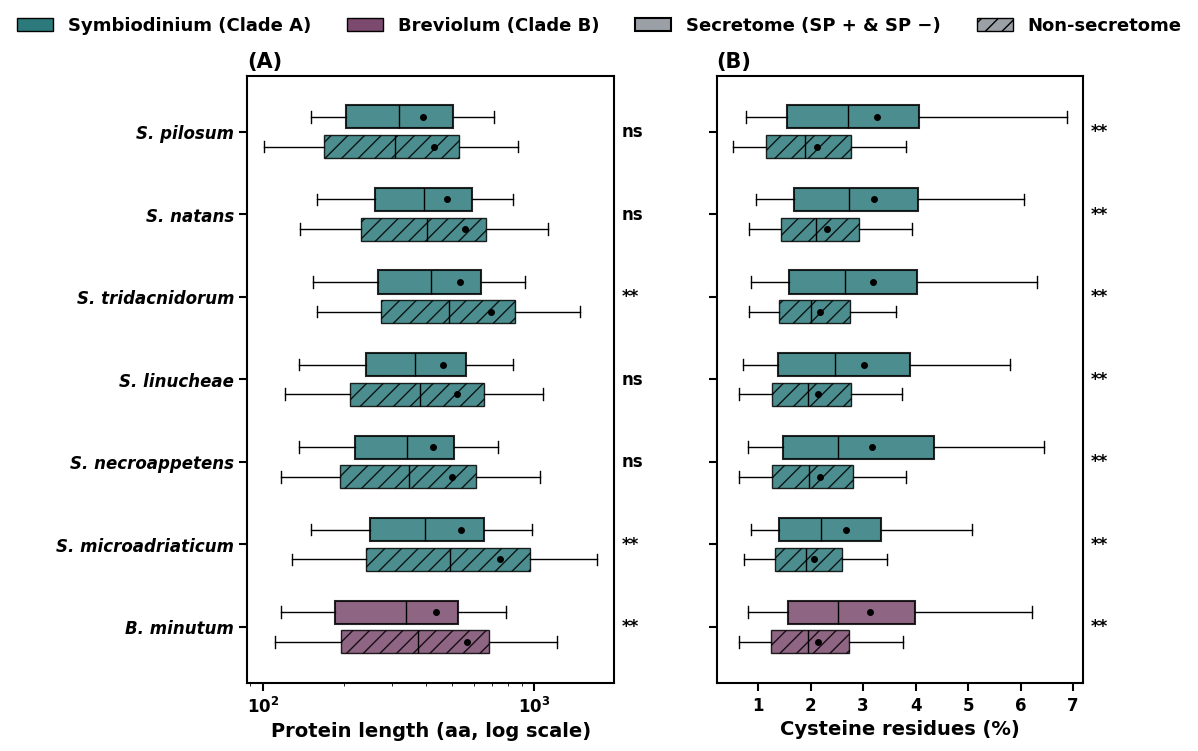


Saved:
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_features.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_stats.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.png
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.pdf
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.svg


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from Bio import SeqIO

try:
    from scipy.stats import mannwhitneyu
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

# ============================================================
# PATHS
# ============================================================
project_path = os.path.join(base, "Prediction_vs_Detection")
base_dir     = project_path

data_pre = os.path.join(base, "Publication", "data_pre")
fig_pre  = os.path.join(base, "Publication", "figures_pre")
os.makedirs(data_pre, exist_ok=True)
os.makedirs(fig_pre,  exist_ok=True)

feature_tsv = os.path.join(data_pre, "secretome_vs_nonsecretome_features.tsv")
stats_tsv   = os.path.join(data_pre, "secretome_vs_nonsecretome_stats.tsv")

# ============================================================
# SPECIES + DISPLAY  (7 strains: 6 Symbiodinium + 1 Breviolum)
# ============================================================
species_order = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic", "Bmin"]

label_map = {
    "Spil": "S. pilosum",        "Snat": "S. natans",
    "Stri": "S. tridacnidorum",  "Slin": "S. linucheae",
    "Snec": "S. necroappetens",  "Smic": "S. microadriaticum",
    "Bmin": "B. minutum",
}
fs_prefix = {
    "Spil": "Spil", "Snat": "Snat", "Stri": "Stri", "Slin": "Slin",
    "Snec": "Snec", "Smic": "Smic_jgi", "Bmin": "Bmin",
}
# clade id "A"/"B" -> robust internal key (decoupled from display strings)
clade_of = {sp: ("B" if sp == "Bmin" else "A") for sp in species_order}
clade_display = {"A": "Symbiodinium (clade A)", "B": "Breviolum (clade B)"}

# ============================================================
# FASTA PATH HELPERS + FEATURES
# ============================================================
def nr_proteome_path(prefix):
    return os.path.join(base_dir, prefix, "01_cdhit", f"{prefix}_nr99.faa")
def secretome_pos_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_pos_secretome_final.faa")
def secretome_neg_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_neg_secretome_final.faa")

# Bmin headers differ between proteome and secretome FASTAs; the stable token
# is the gene model id symbB.v1.2.<6 digits>.t<N>. Extract it from either form.
_BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")

def clean_protein_id(raw, sp):
    pid = raw.split()[0]
    if sp == "Bmin":
        m = _BMIN_RE.search(pid)
        if m is None:
            raise ValueError(f"Bmin header did not match expected pattern: {raw!r}")
        return m.group(1)
    return pid

def calc_features(record):
    seq = str(record.seq).replace("*", "").upper()
    seq = "".join(aa for aa in seq if aa.isalpha())
    if len(seq) == 0:
        return None
    length = len(seq)
    cys_pct = (seq.count("C") / length) * 100
    return {"Length_aa": length, "Cys_percent": cys_pct}

def secretome_id_set(prefix, sp):
    ids = set()
    for fa in (secretome_pos_path(prefix), secretome_neg_path(prefix)):
        if not os.path.exists(fa):
            raise FileNotFoundError(f"Missing FASTA: {fa}")
        for rec in SeqIO.parse(fa, "fasta"):
            ids.add(clean_protein_id(rec.id, sp))
    return ids

# ============================================================
# BUILD LONG TABLE  (Secretome = SP+ ∪ SP- ; Non-secretome = proteome − secretome)
# ============================================================
rows = []
print(f"{'Strain':6}  {'secretome_IDs':>13}  {'matched':>8}  {'non_secretome':>13}  {'OK?':>4}")
for sp in species_order:
    prefix  = fs_prefix[sp]
    sec_ids = secretome_id_set(prefix, sp)
    n_match = n_non = 0
    for rec in SeqIO.parse(nr_proteome_path(prefix), "fasta"):
        feat = calc_features(rec)
        if feat is None:
            continue
        pid = clean_protein_id(rec.id, sp)
        is_sec = pid in sec_ids
        feat["Protein_ID"] = pid
        feat["Species"]    = sp
        feat["Group"]      = "Secretome" if is_sec else "Non-secretome"
        rows.append(feat)
        if is_sec: n_match += 1
        else:      n_non   += 1
    ok = "✓" if n_match == len(sec_ids) else "✗"
    print(f"{sp:6}  {len(sec_ids):13d}  {n_match:8d}  {n_non:13d}  {ok:>4}")

df = pd.DataFrame(rows)
df.to_csv(feature_tsv, sep="\t", index=False)
print(f"\nSaved feature table to: {feature_tsv}")

# ============================================================
# STATS  — Mann–Whitney U + Cliff's delta (effect size) per strain/metric
# ============================================================
def cliffs_delta_from_U(U, n1, n2):
    # U is for the FIRST group passed (secretome); delta>0 => secretome larger
    return 2.0 * U / (n1 * n2) - 1.0

def effect_label(d):
    ad = abs(d)
    if ad < 0.147: return "negligible"
    if ad < 0.330: return "small"
    if ad < 0.474: return "medium"
    return "large"

metrics = [
    ("Length_aa",   "Protein length (aa, log scale)", True),
    ("Cys_percent", "Cysteine residues (%)",          False),
]

stat_rows = []
for col, _, _ in metrics:
    for sp in species_order:
        sv = df[(df.Species == sp) & (df.Group == "Secretome")][col].dropna().values
        nv = df[(df.Species == sp) & (df.Group == "Non-secretome")][col].dropna().values
        rec = {"Species": sp, "Metric": col,
               "n_secretome": len(sv), "n_nonsecretome": len(nv),
               "median_secretome": np.median(sv) if len(sv) else np.nan,
               "median_nonsecretome": np.median(nv) if len(nv) else np.nan}
        if HAVE_SCIPY and len(sv) and len(nv):
            U, p = mannwhitneyu(sv, nv, alternative="two-sided")
            d = cliffs_delta_from_U(U, len(sv), len(nv))
            rec.update({"U": U, "p_value": p,
                        "cliffs_delta": d, "effect_size": effect_label(d)})
        else:
            rec.update({"U": np.nan, "p_value": np.nan,
                        "cliffs_delta": np.nan, "effect_size": ""})
        stat_rows.append(rec)
stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(stats_tsv, sep="\t", index=False)
print(f"Saved stats table to: {stats_tsv}")
print(stats_df.to_string(index=False))

# quick (metric, sp) -> p lookup for the plot
p_lookup = {(r.Metric, r.Species): r.p_value for r in stats_df.itertuples()}

# ============================================================
# STYLE  (house colours: teal = clade A, purple = clade B)
# ============================================================
plt.rcParams["svg.fonttype"]     = "none"
plt.rcParams["font.weight"]      = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.family"]      = "DejaVu Sans"

clade_fill = {"A": "#2C7A7B", "B": "#7C4A6E"}   # teal / purple
LEGEND_GREY = "#9AA0A6"
WHIS = (10, 90)

def p_to_stars(p):
    # three levels only: ns / * / **
    if not np.isfinite(p): return "ns"
    if p < 1e-2: return "**"
    if p < 5e-2: return "*"
    return "ns"

# ============================================================
# Y POSITIONS
# ============================================================
n = len(species_order)
y = np.arange(n) + 1
delta = 0.18

# ============================================================
# PANEL DRAW HELPER  (full frame: all four spines visible)
# ============================================================
def draw_panel(ax, col, xlabel, logscale, letter):
    sec_vals = [df[(df.Species == sp) & (df.Group == "Secretome")][col].dropna().values
                for sp in species_order]
    non_vals = [df[(df.Species == sp) & (df.Group == "Non-secretome")][col].dropna().values
                for sp in species_order]

    bp_sec = ax.boxplot(sec_vals, positions=y - delta, vert=False, widths=0.28,
                        showfliers=False, patch_artist=True, whis=WHIS)
    bp_non = ax.boxplot(non_vals, positions=y + delta, vert=False, widths=0.28,
                        showfliers=False, patch_artist=True, whis=WHIS)

    for i, (b_sec, b_non) in enumerate(zip(bp_sec["boxes"], bp_non["boxes"])):
        c = clade_fill[clade_of[species_order[i]]]
        b_sec.set_facecolor(c); b_sec.set_alpha(0.85)
        b_sec.set_edgecolor("k"); b_sec.set_linewidth(1.5)
        b_non.set_facecolor(c); b_non.set_alpha(0.85)
        b_non.set_edgecolor("k"); b_non.set_linewidth(1.0); b_non.set_hatch("//")
    for k in ["whiskers", "caps", "medians"]:
        for ln in bp_sec[k] + bp_non[k]:
            ln.set_color("k"); ln.set_linewidth(1.0)

    sec_mean = [np.mean(v) if len(v) else np.nan for v in sec_vals]
    non_mean = [np.mean(v) if len(v) else np.nan for v in non_vals]
    ax.scatter(sec_mean, y - delta, s=16, c="k", zorder=4)
    ax.scatter(non_mean, y + delta, s=16, c="k", zorder=4)

    # significance stars (just outside the right frame)
    for i, sp in enumerate(species_order):
        p = p_lookup.get((col, sp), np.nan)
        ax.text(1.02, y[i], p_to_stars(p),
                transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=12, fontweight="bold")

    if logscale:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel, fontsize=14, fontweight="bold")
    ax.set_title(letter, loc="left", fontsize=15, fontweight="bold")

    # full frame — all four spines
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=12, width=1.5, length=6)
    for t in ax.get_xticklabels():
        t.set_fontweight("bold")

# ============================================================
# FIGURE — 1 x 2 (length | cysteine)
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 7.5), sharey=True,
    gridspec_kw={"wspace": 0.28}
)

draw_panel(ax1, "Length_aa",   "Protein length (aa, log scale)", True,  "(A)")
draw_panel(ax2, "Cys_percent", "Cysteine residues (%)",          False, "(B)")

ax1.set_yticks(y)
ax1.set_yticklabels([label_map[s] for s in species_order])
for t in ax1.get_yticklabels():
    t.set_fontstyle("italic"); t.set_fontweight("bold")
ax1.invert_yaxis()

legend_handles = [
    Patch(facecolor=clade_fill["A"], edgecolor="k", label="Symbiodinium (Clade A)"),
    Patch(facecolor=clade_fill["B"], edgecolor="k", label="Breviolum (Clade B)"),
    Patch(facecolor=LEGEND_GREY, edgecolor="k", linewidth=1.5,
          label="Secretome (SP + & SP −)"),
    Patch(facecolor=LEGEND_GREY, edgecolor="k", linewidth=1.0, hatch="//",
          label="Non-secretome"),
]
fig.legend(handles=legend_handles, prop={"size": 13, "weight": "bold"},
           loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=4, frameon=False)

fig.subplots_adjust(left=0.18, right=0.94, top=0.90, bottom=0.09, wspace=0.28)

# ============================================================
# SAVE
# ============================================================
stem = os.path.join(fig_pre, "Fig_secretome_vs_nonsecretome")
for ext in ("png", "pdf", "svg"):
    fig.savefig(f"{stem}.{ext}", dpi=600 if ext == "png" else None, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(feature_tsv)
print(stats_tsv)
for ext in ("png", "pdf", "svg"):
    print(f"{stem}.{ext}")

Strain  secretome_IDs   matched  non_secretome   OK?
Spil              521       521          22728     ✓
Snat             1257      1257          33118     ✓
Stri             1343      1343          40436     ✓
Slin              998       998          31004     ✓
Snec              981       981          34585     ✓
Smic              791       791          42124     ✓
Bmin              984       984          44261     ✓

Saved feature table to: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_features.tsv
Saved stats table to: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_stats.tsv
Species      Metric  n_secretome  n_nonsecretome  median_secretome  median_nonsecretome          U      p_value  cliffs_delta effect_size     p_adj_BH  significant_FDR
   Spil   Length_aa          521           22728        319.000000           306.000000  6177421.0 9.002672e-02      0.043370  negligible 1.575468e-01            Fals

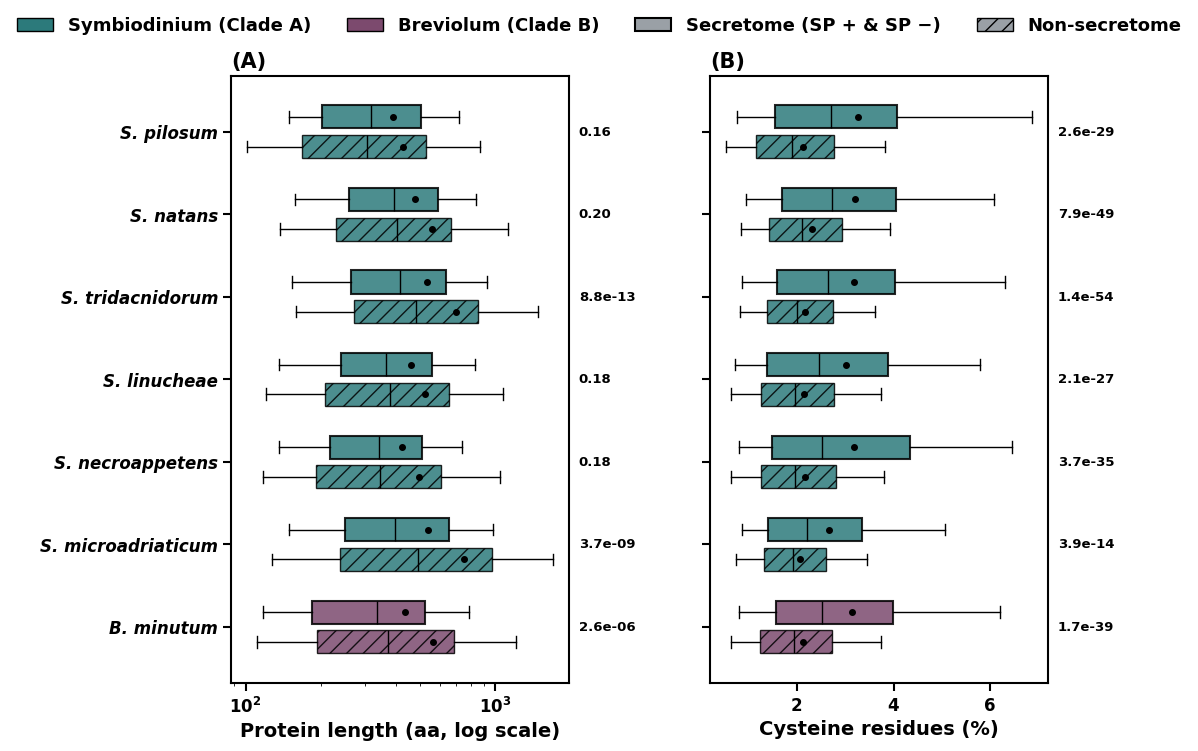


Saved:
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_features.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/secretome_vs_nonsecretome_stats.tsv
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.png
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.pdf
/content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretome_vs_nonsecretome.svg


In [3]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from Bio import SeqIO

try:
    from scipy.stats import mannwhitneyu
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

# ============================================================
# PATHS
# ============================================================
project_path = os.path.join(base, "Prediction_vs_Detection")
base_dir     = project_path

data_pre = os.path.join(base, "Publication", "data_pre")
fig_pre  = os.path.join(base, "Publication", "figures_pre")
os.makedirs(data_pre, exist_ok=True)
os.makedirs(fig_pre,  exist_ok=True)

feature_tsv = os.path.join(data_pre, "secretome_vs_nonsecretome_features.tsv")
stats_tsv   = os.path.join(data_pre, "secretome_vs_nonsecretome_stats.tsv")

# ============================================================
# SPECIES + DISPLAY  (7 strains: 6 Symbiodinium + 1 Breviolum)
# ============================================================
species_order = ["Spil", "Snat", "Stri", "Slin", "Snec", "Smic", "Bmin"]

label_map = {
    "Spil": "S. pilosum",        "Snat": "S. natans",
    "Stri": "S. tridacnidorum",  "Slin": "S. linucheae",
    "Snec": "S. necroappetens",  "Smic": "S. microadriaticum",
    "Bmin": "B. minutum",
}
fs_prefix = {
    "Spil": "Spil", "Snat": "Snat", "Stri": "Stri", "Slin": "Slin",
    "Snec": "Snec", "Smic": "Smic_jgi", "Bmin": "Bmin",
}
clade_of = {sp: ("B" if sp == "Bmin" else "A") for sp in species_order}
clade_display = {"A": "Symbiodinium (clade A)", "B": "Breviolum (clade B)"}

# ============================================================
# FASTA PATH HELPERS + FEATURES
# ============================================================
def nr_proteome_path(prefix):
    return os.path.join(base_dir, prefix, "01_cdhit", f"{prefix}_nr99.faa")
def secretome_pos_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_pos_secretome_final.faa")
def secretome_neg_path(prefix):
    return os.path.join(base_dir, prefix, "09_final", f"{prefix}_SP_neg_secretome_final.faa")

_BMIN_RE = re.compile(r"(symbB\.v1\.2\.\d{6}\.t\d+)")

def clean_protein_id(raw, sp):
    pid = raw.split()[0]
    if sp == "Bmin":
        m = _BMIN_RE.search(pid)
        if m is None:
            raise ValueError(f"Bmin header did not match expected pattern: {raw!r}")
        return m.group(1)
    return pid

def calc_features(record):
    seq = str(record.seq).replace("*", "").upper()
    seq = "".join(aa for aa in seq if aa.isalpha())
    if len(seq) == 0:
        return None
    length = len(seq)
    cys_pct = (seq.count("C") / length) * 100
    return {"Length_aa": length, "Cys_percent": cys_pct}

def secretome_id_set(prefix, sp):
    ids = set()
    for fa in (secretome_pos_path(prefix), secretome_neg_path(prefix)):
        if not os.path.exists(fa):
            raise FileNotFoundError(f"Missing FASTA: {fa}")
        for rec in SeqIO.parse(fa, "fasta"):
            ids.add(clean_protein_id(rec.id, sp))
    return ids

# ============================================================
# BUILD LONG TABLE  (Secretome = SP+ ∪ SP- ; Non-secretome = proteome − secretome)
# ============================================================
rows = []
print(f"{'Strain':6}  {'secretome_IDs':>13}  {'matched':>8}  {'non_secretome':>13}  {'OK?':>4}")
for sp in species_order:
    prefix  = fs_prefix[sp]
    sec_ids = secretome_id_set(prefix, sp)
    n_match = n_non = 0
    for rec in SeqIO.parse(nr_proteome_path(prefix), "fasta"):
        feat = calc_features(rec)
        if feat is None:
            continue
        pid = clean_protein_id(rec.id, sp)
        is_sec = pid in sec_ids
        feat["Protein_ID"] = pid
        feat["Species"]    = sp
        feat["Group"]      = "Secretome" if is_sec else "Non-secretome"
        rows.append(feat)
        if is_sec: n_match += 1
        else:      n_non   += 1
    ok = "✓" if n_match == len(sec_ids) else "✗"
    print(f"{sp:6}  {len(sec_ids):13d}  {n_match:8d}  {n_non:13d}  {ok:>4}")

df = pd.DataFrame(rows)
df.to_csv(feature_tsv, sep="\t", index=False)
print(f"\nSaved feature table to: {feature_tsv}")

# ============================================================
# STATS  — Mann–Whitney U + Cliff's delta + BH-FDR correction (per metric, m=7)
# ============================================================
def cliffs_delta_from_U(U, n1, n2):
    # U is for the FIRST group passed (secretome); delta>0 => secretome larger
    return 2.0 * U / (n1 * n2) - 1.0

def effect_label(d):
    ad = abs(d)
    if ad < 0.147: return "negligible"
    if ad < 0.330: return "small"
    if ad < 0.474: return "medium"
    return "large"

def bh_adjust(pvals):
    """Benjamini–Hochberg FDR. Returns adjusted p-values (q), NaNs preserved."""
    p = np.asarray(pvals, dtype=float)
    finite_idx = [i for i in range(len(p)) if np.isfinite(p[i])]
    m = len(finite_idx)
    q = np.full(len(p), np.nan)
    if m == 0:
        return q
    order = sorted(finite_idx, key=lambda i: p[i])   # ascending by p
    running_min = 1.0
    for rank in range(m, 0, -1):                      # step-up: largest -> smallest
        idx = order[rank - 1]
        val = p[idx] * m / rank
        running_min = min(running_min, val)
        q[idx] = min(running_min, 1.0)
    return q

metrics = [
    ("Length_aa",   "Protein length (aa, log scale)", True),
    ("Cys_percent", "Cysteine residues (%)",          False),
]

stat_rows = []
for col, _, _ in metrics:
    recs = []
    for sp in species_order:
        sv = df[(df.Species == sp) & (df.Group == "Secretome")][col].dropna().values
        nv = df[(df.Species == sp) & (df.Group == "Non-secretome")][col].dropna().values
        rec = {"Species": sp, "Metric": col,
               "n_secretome": len(sv), "n_nonsecretome": len(nv),
               "median_secretome": np.median(sv) if len(sv) else np.nan,
               "median_nonsecretome": np.median(nv) if len(nv) else np.nan}
        if HAVE_SCIPY and len(sv) and len(nv):
            U, p = mannwhitneyu(sv, nv, alternative="two-sided")
            d = cliffs_delta_from_U(U, len(sv), len(nv))
            rec.update({"U": U, "p_value": p,
                        "cliffs_delta": d, "effect_size": effect_label(d)})
        else:
            rec.update({"U": np.nan, "p_value": np.nan,
                        "cliffs_delta": np.nan, "effect_size": ""})
        recs.append(rec)
    # BH correction across the 7 strains of THIS metric
    q = bh_adjust([r["p_value"] for r in recs])
    for r, qv in zip(recs, q):
        r["p_adj_BH"]        = qv
        r["significant_FDR"] = bool(np.isfinite(qv) and qv < 0.05)
    stat_rows.extend(recs)

stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(stats_tsv, sep="\t", index=False)
print(f"Saved stats table to: {stats_tsv}")
print(stats_df.to_string(index=False))

# (metric, sp) -> adjusted p for the plot
padj_lookup = {(r.Metric, r.Species): r.p_adj_BH for r in stats_df.itertuples()}

# ============================================================
# STYLE  (house colours: teal = clade A, purple = clade B)
# ============================================================
plt.rcParams["svg.fonttype"]     = "none"
plt.rcParams["font.weight"]      = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.family"]      = "DejaVu Sans"

clade_fill = {"A": "#2C7A7B", "B": "#7C4A6E"}   # teal / purple
LEGEND_GREY = "#9AA0A6"
WHIS = (10, 90)

def fmt_padj(p):
    """Compact adjusted-p label; floors underflow instead of printing 0."""
    if not np.isfinite(p): return "n/a"
    if p < 1e-300:         return "<1e-300"
    if p >= 0.05:          return f"{p:.2f}"    # ns-range: show plainly
    return f"{p:.1e}"                            # significant: scientific

# ============================================================
# Y POSITIONS
# ============================================================
n = len(species_order)
y = np.arange(n) + 1
delta = 0.18

# ============================================================
# PANEL DRAW HELPER  (full frame; adjusted p-value labels)
# ============================================================
def draw_panel(ax, col, xlabel, logscale, letter):
    sec_vals = [df[(df.Species == sp) & (df.Group == "Secretome")][col].dropna().values
                for sp in species_order]
    non_vals = [df[(df.Species == sp) & (df.Group == "Non-secretome")][col].dropna().values
                for sp in species_order]

    bp_sec = ax.boxplot(sec_vals, positions=y - delta, vert=False, widths=0.28,
                        showfliers=False, patch_artist=True, whis=WHIS)
    bp_non = ax.boxplot(non_vals, positions=y + delta, vert=False, widths=0.28,
                        showfliers=False, patch_artist=True, whis=WHIS)

    for i, (b_sec, b_non) in enumerate(zip(bp_sec["boxes"], bp_non["boxes"])):
        c = clade_fill[clade_of[species_order[i]]]
        b_sec.set_facecolor(c); b_sec.set_alpha(0.85)
        b_sec.set_edgecolor("k"); b_sec.set_linewidth(1.5)
        b_non.set_facecolor(c); b_non.set_alpha(0.85)
        b_non.set_edgecolor("k"); b_non.set_linewidth(1.0); b_non.set_hatch("//")
    for k in ["whiskers", "caps", "medians"]:
        for ln in bp_sec[k] + bp_non[k]:
            ln.set_color("k"); ln.set_linewidth(1.0)

    sec_mean = [np.mean(v) if len(v) else np.nan for v in sec_vals]
    non_mean = [np.mean(v) if len(v) else np.nan for v in non_vals]
    ax.scatter(sec_mean, y - delta, s=16, c="k", zorder=4)
    ax.scatter(non_mean, y + delta, s=16, c="k", zorder=4)

    # BH-adjusted p-value, just outside the right frame
    for i, sp in enumerate(species_order):
        q = padj_lookup.get((col, sp), np.nan)
        ax.text(1.03, y[i], fmt_padj(q),
                transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=9.5, fontweight="bold")

    if logscale:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel, fontsize=14, fontweight="bold")
    ax.set_title(letter, loc="left", fontsize=15, fontweight="bold")

    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=12, width=1.5, length=6)
    for t in ax.get_xticklabels():
        t.set_fontweight("bold")

# ============================================================
# FIGURE — 1 x 2 (length | cysteine)
# ============================================================
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11.5, 7.5), sharey=True,
    gridspec_kw={"wspace": 0.42}
)

draw_panel(ax1, "Length_aa",   "Protein length (aa, log scale)", True,  "(A)")
draw_panel(ax2, "Cys_percent", "Cysteine residues (%)",          False, "(B)")

ax1.set_yticks(y)
ax1.set_yticklabels([label_map[s] for s in species_order])
for t in ax1.get_yticklabels():
    t.set_fontstyle("italic"); t.set_fontweight("bold")
ax1.invert_yaxis()

legend_handles = [
    Patch(facecolor=clade_fill["A"], edgecolor="k", label="Symbiodinium (Clade A)"),
    Patch(facecolor=clade_fill["B"], edgecolor="k", label="Breviolum (Clade B)"),
    Patch(facecolor=LEGEND_GREY, edgecolor="k", linewidth=1.5,
          label="Secretome (SP + & SP −)"),
    Patch(facecolor=LEGEND_GREY, edgecolor="k", linewidth=1.0, hatch="//",
          label="Non-secretome"),
]
fig.legend(handles=legend_handles, prop={"size": 13, "weight": "bold"},
           loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=4, frameon=False)

fig.subplots_adjust(left=0.18, right=0.89, top=0.90, bottom=0.09, wspace=0.42)

# ============================================================
# SAVE
# ============================================================
stem = os.path.join(fig_pre, "Fig_secretome_vs_nonsecretome")
for ext in ("png", "pdf", "svg"):
    fig.savefig(f"{stem}.{ext}", dpi=600 if ext == "png" else None, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(feature_tsv)
print(stats_tsv)
for ext in ("png", "pdf", "svg"):
    print(f"{stem}.{ext}")